# Tugas SIF301 - Natural Language Processing
## Text Preprocessing pada Dataset Ulasan E-Commerce Berbahasa Indonesia

**Nama:** *(Annada Khairatun nisa)*  
**NIM:** *(24146038)*  
**Mata Kuliah:** SIF301 - Natural Language Processing  
**Dataset:** [dipawidia/ecommerce-product-reviews-sentiment](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment)

---

### Daftar Isi
1. Instalasi & Import Library
2. Load Dataset Ulasan E-Commerce Berbahasa Indonesia
3. Eksplorasi Informasi Dataset (Jumlah Data, Kolom, & Distribusi Label Sentimen)
4. Preprocessing Teks (Case Folding, Cleaning, Tokenisasi, Stopword Removal, Stemming)
5. Perbandingan 10 Contoh Teks Sebelum dan Sesudah Preprocessing
6. Analisis Pengaruh Preprocessing terhadap Kualitas Data Teks

## 0. Instalasi & Import Library
Sel berikut memasang library yang dibutuhkan (otomatis dilewati jika sudah terpasang di environment Anda, seperti di Google Colab atau Jupyter lokal).

In [1]:
%pip install -q datasets pandas matplotlib nltk Sastrawi

In [2]:
import re
import time
from functools import lru_cache

import pandas as pd
import matplotlib.pyplot as plt
import nltk
from IPython.display import display
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from datasets import load_dataset
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Unduh resource NLTK yang diperlukan secara diam-diam
for resource in ["punkt", "punkt_tab", "stopwords"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass

# Atur tampilan tabel pandas agar teks panjang tidak terpotong
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


## 1. Load Dataset Ulasan E-Commerce Berbahasa Indonesia
Dataset dimuat langsung dari Hugging Face: `dipawidia/ecommerce-product-reviews-sentiment`.

In [3]:
# Memuat dataset dari Hugging Face
dataset = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")
print("Struktur Dataset Hugging Face:")
print(dataset)

# Menggabungkan seluruh split (train/test/dst.) menjadi satu DataFrame
dfs = []
print("\nRincian jumlah data per split:")
for split_name, split_data in dataset.items():
    temp_df = split_data.to_pandas()
    dfs.append(temp_df)
    print(f"- Split '{split_name}': {len(temp_df):,} baris")

df = pd.concat(dfs, ignore_index=True)

# Identifikasi nama kolom teks dan label sentimen
TEXT_COL = "review" if "review" in df.columns else df.columns[0]
LABEL_COL = "sentimen" if "sentimen" in df.columns else df.columns[-1]

print(f"\nTotal seluruh data: {len(df):,} baris")
print(f"Kolom teks yang digunakan : '{TEXT_COL}'")
print(f"Kolom label sentimen      : '{LABEL_COL}'")

README.md:   0%|          | 0.00/1.51k [00:00<?, ?B/s]

labeledReview.datasetFix.json:   0%|          | 0.00/3.15M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11606 [00:00<?, ? examples/s]

Struktur Dataset Hugging Face:
DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})

Rincian jumlah data per split:
- Split 'train': 11,606 baris

Total seluruh data: 11,606 baris
Kolom teks yang digunakan : 'review'
Kolom label sentimen      : 'sentimen'


## 2. Informasi Dataset
Menampilkan jumlah data, nama dan tipe kolom, pengecekan data kosong/duplikat, contoh data awal, serta distribusi label sentimen.

In [4]:
print("=" * 60)
print("INFORMASI UMUM DATASET")
print("=" * 60)
print(f"Jumlah Baris (Data) : {df.shape[0]:,}")
print(f"Jumlah Kolom        : {df.shape[1]}")
print(f"Nama Kolom          : {list(df.columns)}")
print("\nTipe Data & Nilai Non-Null:")
df.info()

print("\nJumlah Missing Values per Kolom:")
print(df.isnull().sum())

print(f"\nJumlah Data Duplikat (berdasarkan kolom '{TEXT_COL}'): {df.duplicated(subset=[TEXT_COL]).sum():,}")

print("\n5 Contoh Data Pertama:")
display(df.head())

INFORMASI UMUM DATASET
Jumlah Baris (Data) : 11,606
Jumlah Kolom        : 3
Nama Kolom          : ['review', 'translate', 'sentimen']

Tipe Data & Nilai Non-Null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     11606 non-null  object
 1   translate  11606 non-null  object
 2   sentimen   11606 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 272.1+ KB

Jumlah Missing Values per Kolom:
review       0
translate    0
sentimen     0
dtype: int64

Jumlah Data Duplikat (berdasarkan kolom 'review'): 7

5 Contoh Data Pertama:


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,"sound and mic satisfied. I only ordered the one that was on and I made sure that it clicked again, but the one that came didn't turn on",0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay attention again",0
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(,"product quality is good. affordable prices and very fast delivery. I've already ordered here, it's okay, but unfortunately, if you make a gift, you can't bring it with a greeting card or wrap it in gift paper :(",0
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit","overall is good, the buttons all work, but the packaging is lacking because it's dented and torn a little",0


Distribusi Label Sentimen:


,Kode Label,Kategori Sentimen,Jumlah Data,Persentase (%)
0,0,Negatif (0),5803,50.0
1,1,Positif (1),5803,50.0


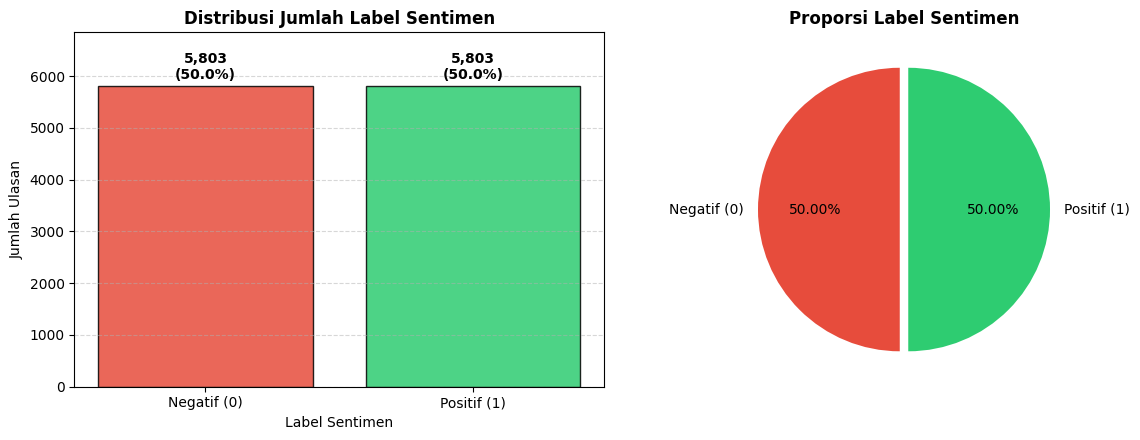

In [5]:
# Distribusi Label Sentimen
label_map = {
    0: "Negatif (0)",
    1: "Positif (1)",
    "0": "Negatif (0)",
    "1": "Positif (1)",
}

distribusi = df[LABEL_COL].value_counts().sort_index()
persentase = (df[LABEL_COL].value_counts(normalize=True).sort_index() * 100).round(2)

df_distribusi = pd.DataFrame({
    "Kode Label": distribusi.index,
    "Kategori Sentimen": [label_map.get(idx, str(idx)) for idx in distribusi.index],
    "Jumlah Data": distribusi.values,
    "Persentase (%)": persentase.values,
})

print("Distribusi Label Sentimen:")
display(df_distribusi)

# Visualisasi Distribusi Label Sentimen
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ["#e74c3c", "#2ecc71", "#3498db", "#f39c12"][:len(df_distribusi)]

# Bar Chart
bars = axes[0].bar(df_distribusi["Kategori Sentimen"], df_distribusi["Jumlah Data"], color=colors, edgecolor="black", alpha=0.85)
axes[0].set_title("Distribusi Jumlah Label Sentimen", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Label Sentimen")
axes[0].set_ylabel("Jumlah Ulasan")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for bar, count, pct in zip(bars, df_distribusi["Jumlah Data"], df_distribusi["Persentase (%)"]):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (df_distribusi["Jumlah Data"].max() * 0.015),
        f"{count:,}\n({pct}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )
axes[0].set_ylim(0, df_distribusi["Jumlah Data"].max() * 1.18)

# Pie Chart
axes[1].pie(
    df_distribusi["Jumlah Data"],
    labels=df_distribusi["Kategori Sentimen"],
    autopct="%1.2f%%",
    startangle=90,
    colors=colors,
    explode=[0.03] * len(df_distribusi),
    textprops={"fontsize": 10},
)
axes[1].set_title("Proporsi Label Sentimen", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

## 3. Preprocessing Teks
Tahapan preprocessing teks yang diterapkan secara berurutan pada kolom `review`:
1. **Case Folding**: mengubah seluruh huruf menjadi huruf kecil (*lowercase*).
2. **Cleaning**: menghapus URL, tag HTML, mention/hashtag, angka, tanda baca, emoji, dan karakter khusus lainnya.
3. **Tokenisasi**: memecah kalimat menjadi daftar kata (*token*).
4. **Stopword Removal**: menghapus kata-kata umum Bahasa Indonesia yang kurang membawa informasi sentimen (gabungan kamus `Sastrawi` dan `NLTK`).
5. **Stemming**: mengubah kata berimbuhan menjadi kata dasar Bahasa Indonesia menggunakan `Sastrawi` *(dilengkapi caching `@lru_cache` agar eksekusi pada ribuan ulasan jauh lebih cepat)*.

In [6]:
# 1. Inisialisasi daftar stopword Bahasa Indonesia (Sastrawi + NLTK)
sastrawi_stopwords = set(StopWordRemoverFactory().get_stop_words())
try:
    nltk_stopwords = set(stopwords.words("indonesian"))
except LookupError:
    nltk_stopwords = set()

STOPWORDS_ID = sastrawi_stopwords.union(nltk_stopwords)
print(f"Jumlah kamus stopword Bahasa Indonesia: {len(STOPWORDS_ID)} kata")

# 2. Inisialisasi Stemmer Bahasa Indonesia (Sastrawi) dengan caching
stemmer = StemmerFactory().create_stemmer()

@lru_cache(maxsize=None)
def stem_kata(kata: str) -> str:
    return stemmer.stem(kata)

# --- Definisi 5 Fungsi Tahapan Preprocessing ---

def case_folding(text: str) -> str:
    """Tahap 1: Mengubah seluruh teks menjadi huruf kecil."""
    if pd.isna(text):
        return ""
    return str(text).lower()

def cleaning(text: str) -> str:
    """Tahap 2: Menghapus URL, tag HTML, angka, tanda baca, dan karakter khusus."""
    # Hapus URL (http, https, www)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    # Hapus tag HTML
    text = re.sub(r"<.*?>", " ", text)
    # Hapus mention dan hashtag
    text = re.sub(r"[@#]\w+", " ", text)
    # Hapus angka
    text = re.sub(r"\d+", " ", text)
    # Hapus tanda baca, emoji, dan karakter non-alfabet
    text = re.sub(r"[^a-z\s]", " ", text)
    # Rapikan spasi berlebih
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenisasi(text: str) -> list:
    """Tahap 3: Memisahkan teks menjadi daftar kata (token)."""
    if not text:
        return []
    try:
        return word_tokenize(text)
    except LookupError:
        return text.split()

def stopword_removal(tokens: list) -> list:
    """Tahap 4: Menghapus stopword dan token tunggal 1 huruf sisa pembersihan."""
    return [kata for kata in tokens if kata not in STOPWORDS_ID and len(kata) > 1]

def stemming(tokens: list) -> list:
    """Tahap 5: Mengubah setiap kata menjadi bentuk dasar (stem)."""
    return [stem_kata(kata) for kata in tokens]

print("Seluruh fungsi preprocessing siap digunakan!")

Jumlah kamus stopword Bahasa Indonesia: 774 kata
Seluruh fungsi preprocessing siap digunakan!


In [7]:
# Menjalankan seluruh tahapan preprocessing pada seluruh dataset
start_time = time.time()

print("Menjalankan Tahap 1: Case Folding...")
df["case_folding"] = df[TEXT_COL].apply(case_folding)

print("Menjalankan Tahap 2: Cleaning...")
df["cleaned"] = df["case_folding"].apply(cleaning)

print("Menjalankan Tahap 3: Tokenisasi...")
df["tokens"] = df["cleaned"].apply(tokenisasi)

print("Menjalankan Tahap 4: Stopword Removal...")
df["no_stopwords"] = df["tokens"].apply(stopword_removal)

print("Menjalankan Tahap 5: Stemming (Sastrawi + cache)...")
df["stemmed_tokens"] = df["no_stopwords"].apply(stemming)

# Gabungkan kembali token hasil akhir menjadi string teks bersih
df["teks_preprocessing"] = df["stemmed_tokens"].apply(lambda tokens: " ".join(tokens))

elapsed = time.time() - start_time
print(f"\nPreprocessing selesai untuk {len(df):,} ulasan dalam {elapsed:.2f} detik!")
print(f"Total kata unik yang di-stem (cache): {stem_kata.cache_info().currsize:,} kata")

Menjalankan Tahap 1: Case Folding...
Menjalankan Tahap 2: Cleaning...
Menjalankan Tahap 3: Tokenisasi...
Menjalankan Tahap 4: Stopword Removal...
Menjalankan Tahap 5: Stemming (Sastrawi + cache)...

Preprocessing selesai untuk 11,606 ulasan dalam 664.81 detik!
Total kata unik yang di-stem (cache): 12,046 kata


In [8]:
# Demonstrasi proses bertahap pada 1 contoh ulasan (untuk memudahkan pengecekan tiap tahap)
contoh_idx = 0
print("=" * 80)
print("CONTOH DETAIL PERUBAHAN TEKS PADA SETIAP TAHAP PREPROCESSING")
print("=" * 80)
print(f"0. Teks Asli        : {df.loc[contoh_idx, TEXT_COL]}")
print(f"1. Case Folding     : {df.loc[contoh_idx, 'case_folding']}")
print(f"2. Cleaning         : {df.loc[contoh_idx, 'cleaned']}")
print(f"3. Tokenisasi       : {df.loc[contoh_idx, 'tokens']}")
print(f"4. Stopword Removal : {df.loc[contoh_idx, 'no_stopwords']}")
print(f"5. Stemming         : {df.loc[contoh_idx, 'stemmed_tokens']}")
print(f"   Hasil Akhir Teks : {df.loc[contoh_idx, 'teks_preprocessing']}")

CONTOH DETAIL PERUBAHAN TEKS PADA SETIAP TAHAP PREPROCESSING
0. Teks Asli        : Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
1. Case Folding     : suara dan mic puas. hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
2. Cleaning         : suara dan mic puas hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
3. Tokenisasi       : ['suara', 'dan', 'mic', 'puas', 'hanya', 'saya', 'pesan', 'yg', 'nyala', 'dan', 'sudah', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'datang', 'ga', 'nyala']
4. Stopword Removal : ['suara', 'mic', 'puas', 'pesan', 'yg', 'nyala', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'ga', 'nyala']
5. Stemming         : ['suara', 'mic', 'puas', 'pesan', 'yg', 'nyala', 'sy', 'pasti', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'ga', 'nyala']
   Hasil Akhir Teks : suara mic puas pesan yg nyala sy pasti lg klik yg

## 4. Menampilkan 10 Contoh Teks Sebelum dan Sesudah Preprocessing
Berikut disajikan 10 sampel ulasan (5 ulasan sentimen negatif dan 5 ulasan sentimen positif) yang membandingkan teks asli sebelum preprocessing dengan teks akhir sesudah seluruh tahapan preprocessing.

In [9]:
# Mengambil 10 sampel representatif (5 Negatif & 5 Positif dengan random_state tetap agar konsisten)
sample_parts = []
for label_val in sorted(df[LABEL_COL].dropna().unique()):
    subset = df[df[LABEL_COL] == label_val]
    n_take = min(5, len(subset))
    sample_parts.append(subset.sample(n=n_take, random_state=42))

df_sample = pd.concat(sample_parts, ignore_index=True).head(10)

# Jika total sampel kurang dari 10 (misal hanya 1 label), lengkapi dari dataset utama
if len(df_sample) < 10:
    df_sample = df.sample(n=10, random_state=42).reset_index(drop=True)

tabel_perbandingan = pd.DataFrame({
    "No": range(1, len(df_sample) + 1),
    "Sentimen": df_sample[LABEL_COL].map(lambda x: label_map.get(x, str(x))),
    "Sebelum Preprocessing": df_sample[TEXT_COL],
    "Sesudah Preprocessing": df_sample["teks_preprocessing"],
})

# Tampilkan tabel dengan perataan kiri agar rapi dibaca dan mudah di-screenshot untuk laporan PDF
try:
    display(
        tabel_perbandingan.style
        .hide(axis="index")
        .set_properties(**{"text-align": "left", "vertical-align": "top"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
    )
except ImportError:
    display(tabel_perbandingan)

No,Sentimen,Sebelum Preprocessing,Sesudah Preprocessing
1,Negatif (0),…hanya 13 Channel? Mudah2an besok atau minggu depan nambah ya 😄,channel mudah an besok minggu nambah
2,Negatif (0),"bintang 1 dulu, ini kenapa backlight keyboardnya gak nyala ya ? pakai batre lagi?",bintang backlight keyboardnya gak nyala pakai batre
3,Negatif (0),"Pengiriman cepat kemarin pesan, skrng sudah datang, Kualitas bagus sesuai harga, cuma klik tombol forward n back nya terlalu dalam n kyk tertukar gk sesuai di buku petunjuk, tapi mantaap mouse seri terbarunya, sblmnya pke yg Fantech Raigor W4 semoga awet kyk seri sblm nya..",kirim cepat kemarin pesan skrng kualitas bagus sesuai harga klik tombol forward back nya kyk tukar gk sesuai buku tunjuk mantaap mouse seri baru sblmnya pke yg fantech raigor moga awet kyk seri sblm nya
4,Negatif (0),"Harga:Lumayan Bahan/Material:Bagus Kegunaan:membantu Sebenernya dari bahan itu good bgt, gx ada keluhan sama skli, cuman dus nya aja terlalu sempit udh gtu gx di ksoh skat per spatula, jdi kegesek2 jdi ada yg baret/lecet, si cantolan rak nya pdhal jgn di psng drsnanya, jdi ada yg patah, mungkin krna packing nya jga terlalu tipis, buble+plastik doang",harga lumayan bahan material bagus guna bantu sebenernya bahan good bgt gx keluh skli cuman dus nya aja sempit udh gtu gx ksoh skat spatula jdi gesek jdi yg baret lecet si cantol rak nya pdhal jgn psng drsnanya jdi yg patah krna packing nya jga tipis buble plastik doang
5,Negatif (0),"komunikasi merupakan suatu hal yang penting dalam kehidupan mahluk hidup, salah satunya yaitu manusia. Tanpa komunikasi, dapat dikatakan manusia tidak layak hidup. Karena tidak ada komunikasi baik pada diri sendiri apalagi orang lain. Oleh sebab itu komunikasi begitu penting dan wajib dilakukan.",komunikasi hidup mahluk hidup salah satu manusia komunikasi manusia layak hidup komunikasi orang komunikasi wajib
6,Positif (1),"Pengiriman standar, packing standar kardusnya, overall bagus pengiriman.",kirim standar packing standar kardus overall bagus kirim
7,Positif (1),"Alhamdulillah barang sudah sampai dengan selamat, tidak ada yang cacat atau penyok, sesuai etalase dan diskripsi asli merk Maspion SNI, toko amanah seller ramah kurirnya baru.. semoga toko sukses 👍👍",alhamdulillah barang selamat cacat penyok sesuai etalase skripsi asli merk maspion sni toko amanah seller ramah kurir moga toko sukses
8,Positif (1),barang bagus dan packing nya sangat bagus terbaik👍,barang bagus packing nya bagus baik
9,Positif (1),"pelayanan sangat cepat. order pagi, sore sampai.",layan cepat order pagi sore
10,Positif (1),mantabhh,mantabhh


In [10]:
# Ringkasan kuantitatif dampak preprocessing terhadap dataset (mendukung analisis bagian 5)
raw_tokens_series = df[TEXT_COL].fillna("").astype(str).apply(lambda s: s.split())
clean_tokens_series = df["stemmed_tokens"]

total_kata_sebelum = raw_tokens_series.apply(len).sum()
total_kata_sesudah = clean_tokens_series.apply(len).sum()

avg_kata_sebelum = raw_tokens_series.apply(len).mean()
avg_kata_sesudah = clean_tokens_series.apply(len).mean()

vocab_sebelum = len(set(kata for tokens in raw_tokens_series for kata in tokens))
vocab_sesudah = len(set(kata for tokens in clean_tokens_series for kata in tokens))

reduksi_kata_pct = (1 - total_kata_sesudah / total_kata_sebelum) * 100
reduksi_vocab_pct = (1 - vocab_sesudah / vocab_sebelum) * 100

df_ringkasan = pd.DataFrame({
    "Metrik": [
        "Total Token (Kata)",
        "Rata-rata Kata per Ulasan",
        "Jumlah Kosakata Unik (Vocabulary Size)",
    ],
    "Sebelum Preprocessing": [
        f"{total_kata_sebelum:,}",
        f"{avg_kata_sebelum:.2f}",
        f"{vocab_sebelum:,}",
    ],
    "Sesudah Preprocessing": [
        f"{total_kata_sesudah:,}",
        f"{avg_kata_sesudah:.2f}",
        f"{vocab_sesudah:,}",
    ],
    "Perubahan / Reduksi": [
        f"-{reduksi_kata_pct:.2f}%",
        f"-{reduksi_kata_pct:.2f}%",
        f"-{reduksi_vocab_pct:.2f}%",
    ],
})

print("Ringkasan Kuantitatif Dampak Preprocessing:")
try:
    display(df_ringkasan.style.hide(axis="index"))
except ImportError:
    display(df_ringkasan)

Ringkasan Kuantitatif Dampak Preprocessing:


Metrik,Sebelum Preprocessing,Sesudah Preprocessing,Perubahan / Reduksi
Total Token (Kata),"182,871","128,111",-29.94%
Rata-rata Kata per Ulasan,15.76,11.04,-29.94%
Jumlah Kosakata Unik (Vocabulary Size),"26,205","10,034",-61.71%


## 5. Pengaruh Preprocessing terhadap Kualitas Data Teks

Tahapan *text preprocessing* memberikan pengaruh yang signifikan terhadap kualitas data teks ulasan e-commerce sebelum digunakan pada pemodelan NLP (seperti analisis sentimen):

1. **Menghilangkan *Noise* dan Elemen Tidak Relevan (*Cleaning*)**  
   Ulasan e-commerce umumnya banyak mengandung tanda baca berlebih (`!!!`, `...`), angka, simbol, emoji, hingga tautan. Penghapusan elemen tersebut membuat teks lebih bersih sehingga fitur yang dipelajari model hanya berasal dari kata yang relevan.

2. **Menyeragamkan Representasi Kata (*Case Folding* & *Stemming*)**  
   *Case folding* memastikan kata dengan kapitalisasi berbeda (misalnya `"Bagus"`, `"BAGUS"`, dan `"bagus"`) dianggap sama. Selanjutnya, *stemming* menyatukan kata berimbuhan ke bentuk dasarnya (misalnya `"pengiriman"`, `"dikirim"`, `"mengirim"` menjadi `"kirim"`). Hal ini menurunkan ukuran kosakata (*vocabulary size*) dan mengurangi dimensi fitur secara drastis sehingga proses pelatihan model lebih ringan dan tidak mudah *overfitting*.

3. **Memfokuskan Teks pada Kata Bermakna (*Tokenisasi* & *Stopword Removal*)**  
   Setelah teks dipecah menjadi token, penghapusan *stopword* (seperti `"yang"`, `"dan"`, `"di"`, `"dengan"`) membuang kata berfrekuensi tinggi yang tidak membedakan sentimen positif maupun negatif, sehingga bobot kata kunci sentimen (seperti `"bagus"`, `"rusak"`, `"cepet"`, `"kecewa"`) menjadi lebih menonjol.

4. **Catatan/Keterbatasan yang Perlu Diperhatikan**  
   Meskipun meningkatkan kebersihan dan efisiensi data, *preprocessing* yang terlalu agresif juga memiliki risiko pada kasus analisis sentimen:
   - Penghapusan *stopword* tertentu seperti kata negasi (`"tidak"`, `"kurang"`, `"bukan"`) dapat mengubah makna kalimat (misalnya `"tidak bagus"` menjadi `"bagus"`).
   - Bahasa non-baku atau singkatan khas e-commerce Indonesia (seperti `"brg"`, `"bgt"`, `"mantul"`, `"gk"`) tidak otomatis terbakukan oleh *stemmer* standar dan pada pengembangan lanjutan dapat ditangani dengan kamus normalisasi (*slang dictionary*).